# 02 — Preparação dos Dados
**CRISP-DM — etapa 3.** Limpeza, tratamento de faltantes, transformação, junção das bases e divisão treino/teste.
Toda etapa registra quantas linhas sobraram (tabela "funil"), que vai para o artigo.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, carregamento as c, preparacao as p, graficos as g

config.criar_pastas()
g.aplicar_estilo()
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Percentual de usuários amostrados:", config.PERCENTUAL_USUARIOS, "%")

Percentual de usuários amostrados: 15 %


In [2]:
funil = []
A = p.limpar_base_a(c.carregar_base_a(), funil)
b = p.limpar_b_games(c.carregar_b_games(), c.carregar_b_metadata(), funil)
catalogo = p.montar_catalogo(A, b, funil)
print(f"Catálogo unificado: {len(catalogo):,} jogos | com características: {catalogo['tem_features'].mean():.1%}")

Catálogo unificado: 50,872 jogos | com características: 99.2%


### Transformação: texto de características para o TF-IDF
Gêneros + categorias + tags (união das tags de A e B) são normalizados (minúsculas, sem acento) e cada expressão
vira um token único (`Open World` → `open_world`), para o TF-IDF não separar palavras que só fazem sentido juntas.

In [3]:
catalogo.sort_values("total_avaliacoes", ascending=False)[
    ["nome", "genres", "tags_unificadas", "texto_features"]].head(5)

,nome,genres,tags_unificadas,texto_features
14398,Counter-Strike: Global Offensive,"[Action, Free To Play]","[FPS, Shooter, Multiplayer, Competitive, Actio...",action free_to_play multi_player cross_platfor...
47770,PUBG: BATTLEGROUNDS,"[Action, Adventure, Massively Multiplayer, Fre...","[Survival, Shooter, Battle Royale, Multiplayer...",action adventure massively_multiplayer free_to...
13176,Dota 2,"[Action, Strategy, Free To Play]","[Free to Play, MOBA, Multiplayer, Strategy, e-...",action strategy free_to_play multi_player co_o...
12717,Grand Theft Auto V,"[Action, Adventure]","[Open World, Action, Multiplayer, Crime, Autom...",action adventure single_player multi_player pv...
13035,Terraria,"[Action, Adventure, Indie, RPG]","[Open World Survival Craft, Sandbox, Survival,...",action adventure indie rpg single_player multi...


### Tratamento de faltantes

In [4]:
faltantes_cat = pd.DataFrame({
    "sem gênero": catalogo["genres"].map(len).eq(0).mean(),
    "sem categoria": catalogo["categories"].map(len).eq(0).mean(),
    "sem tag": catalogo["tags_unificadas"].map(len).eq(0).mean(),
    "sem nenhuma característica (removido)": (~catalogo["tem_features"]).mean(),
    "sem avaliações": catalogo["total_avaliacoes"].eq(0).mean(),
    "fora da base A (avaliações vieram da base B)": (~catalogo["presente_na_base_a"]).mean(),
}, index=["% do catálogo"]).T
faltantes_cat.to_csv(config.RESULTADOS / "tabela_faltantes_catalogo.csv")
faltantes_cat.style.format("{:.1%}")

,% do catálogo
sem gênero,22.6%
sem categoria,23.1%
sem tag,0.8%
sem nenhuma característica (removido),0.8%
sem avaliações,0.0%
fora da base A (avaliações vieram da base B),22.5%


**Decisões:**
- jogo **sem nenhuma característica** → removido (não há como compará-lo por conteúdo);
- jogo **sem gênero/categoria, mas com tags** → mantido (as tags carregam a informação);
- jogo **fora da base A** → avaliações reconstruídas de `positive_ratio × user_reviews` da base B;
- **avaliações faltantes** → contadas como zero, e o filtro de qualidade exige volume mínimo.

### Filtro de qualidade (proposta do seminário + volume mínimo)

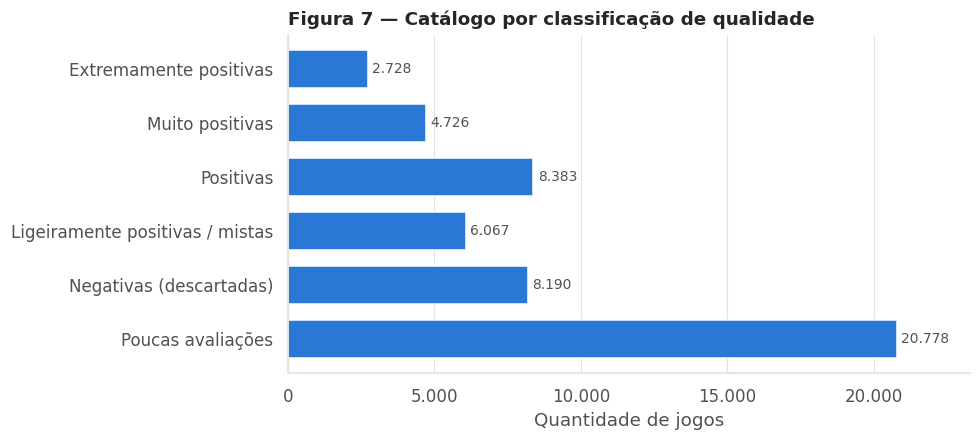

Passam no filtro (>= 50 avaliações e taxa negativa <= 30%): 43.1%


In [5]:
ordem = ["Extremamente positivas", "Muito positivas", "Positivas",
         "Ligeiramente positivas / mistas", "Negativas (descartadas)", "Poucas avaliações"]
dist_q = catalogo["classificacao_qualidade"].value_counts().reindex(ordem, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(dist_q.index[::-1], dist_q.values[::-1], color=g.AZUL, height=0.7)
g.rotular_barras(ax, horizontal=True)
ax.set_title("Figura 7 — Catálogo por classificação de qualidade")
ax.set_xlabel("Quantidade de jogos")
g.eixo_br(ax, "x")
ax.grid(axis="y", visible=False)
g.salvar(fig, "fig07_catalogo_qualidade")
plt.show()
print(f"Passam no filtro (>= {config.MIN_AVALIACOES_QUALIDADE} avaliações e taxa negativa <= "
      f"{config.TAXA_NEGATIVA_DESCARTE:.0%}): {catalogo['passa_filtro_qualidade'].mean():.1%}")

### Por que o limite inferior de Wilson?
A taxa negativa simples trata 3 avaliações positivas em 3 igual a 30 000 em 30 000. O limite inferior do intervalo
de Wilson (95%) corrige isso: com poucas avaliações a incerteza é grande e o valor cai.

In [6]:
exemplo = pd.DataFrame({"positivas": [3, 30, 300, 30000], "total": [3, 33, 330, 33000]})
exemplo["taxa_positiva"] = exemplo["positivas"] / exemplo["total"]
exemplo["wilson_inferior"] = p.limite_inferior_wilson(exemplo["positivas"], exemplo["total"])
exemplo

,positivas,total,taxa_positiva,wilson_inferior
0,3,3,1.0000,0.4385
1,30,33,0.9091,0.7643
2,300,330,0.9091,0.8732
3,30000,33000,0.9091,0.9059


### Interações: limpeza, desbalanceamento e filtros mínimos

In [7]:
recs, _ = c.carregar_recomendacoes()
interacoes = p.preparar_interacoes(recs, catalogo, funil)
del recs
print(f"Interações finais: {len(interacoes):,} | usuários: {interacoes['user_id'].nunique():,} | "
      f"jogos: {interacoes['app_id'].nunique():,}")

Interações finais: 1,935,287 | usuários: 116,305 | jogos: 15,451


**Tratamento do desbalanceamento:** como as avaliações negativas são minoria e o objetivo é recomendar o que
a pessoa vai gostar, usamos apenas as interações positivas como sinal (feedback implícito). O viés de popularidade
(cauda longa) é tratado na avaliação: comparamos com um baseline de popularidade e medimos a cobertura do catálogo.

### Funil da preparação (tabela para o artigo)

In [8]:
tabela_funil = p.funil_para_df(funil)
tabela_funil.to_csv(config.ARQ_FUNIL, index=False)
tabela_funil

,base,etapa,registros,removidos
0,A (metadados),bruto,144981,0
1,A (metadados),sem app_id nulo,144981,0
2,A (metadados),sem app_id duplicado,144981,0
3,A (metadados),com nome preenchido,144965,16
4,B (jogos),bruto,50872,0
5,B (jogos),sem app_id duplicado,50872,0
6,Catálogo (A+B),jogos da base B,50872,0
7,Catálogo (A+B),jogos também presentes na base A,39430,11442
8,B (interações),amostra de usuários,6166612,0
9,B (interações),sem data/usuário/jogo nulo,6166612,0


### Divisão temporal treino/teste
Para cada usuário, os **3 jogos mais recentes** ficam escondidos (teste) e o restante é o histórico (treino).
O perfil usado para recomendar são os últimos 1 ou 5 jogos do histórico. Assim, simulamos a situação real:
"o que essa pessoa vai jogar depois?" — sem usar informação do futuro.

In [9]:
treino, teste = p.divisao_temporal(interacoes)
catalogo_modelo = catalogo[catalogo["app_id"].isin(interacoes["app_id"])].reset_index(drop=True)

print(f"Treino: {len(treino):,} interações | Teste: {len(teste):,} interações")
print(f"Jogos no catálogo do modelo: {len(catalogo_modelo):,}")
print(f"Checagem de vazamento — data máxima do treino <= data mínima do teste por usuário: "
      f"{(treino.groupby('user_id')['date'].max() <= teste.groupby('user_id')['date'].min()).mean():.1%}")

Treino: 1,586,372 interações | Teste: 348,915 interações
Jogos no catálogo do modelo: 15,451
Checagem de vazamento — data máxima do treino <= data mínima do teste por usuário: 100.0%


In [10]:
catalogo_modelo.to_parquet(config.ARQ_CATALOGO, index=False)
interacoes.to_parquet(config.ARQ_INTERACOES, index=False)
treino.to_parquet(config.ARQ_TREINO, index=False)
teste.to_parquet(config.ARQ_TESTE, index=False)
print("Arquivos salvos em", config.DADOS_PROCESSADOS)

Arquivos salvos em /content/steam-recomendador/data/processed
